# THERMOSCOPE · 01 Dataset exploration
Reads `outputs/dataset.csv` and `outputs/dataset_audit.json` (run `python -m thermoscope.run` first).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv('../outputs/dataset.csv'); audit = json.load(open('../outputs/dataset_audit.json'))
audit

{'backend': 'pr', 'backend_version': 'Peng-Robinson (1976), thermoscope.eos_pr', 'seed': 20261115, 'n_fluids': 22, 'requested': 10340, 'valid': 10308, 'rejected': {'saturation_guard': 32, 'invalid_state': 0, 'ambiguous_phase': 0, 'backend_error': 0}, 'duplicates_removed': 0, 'missing_values': 0, 'guard_band': 0.02, 'tr_range': [0.6, 1.6], 'pr_range': [0.03, 3.0], 'sampling': 'per fluid: Tr ~ Uniform, ln Pr ~ Uniform; states with |ln(Pr/Psat)| < guard_band excluded'}

In [2]:
df.head(10)

,fluid,fluid_id,Tr,Pr,omega,Z,ar,hr,sr,gr,lnphi,phase,split,cv_fold
0,Methane,0,1.101887,0.131850,0.0114,0.961050,-0.039464,-0.108804,-0.030390,-0.078414,-0.038685,2,test,-1
1,Methane,0,1.186886,0.119395,0.0114,0.971569,-0.028755,-0.081588,-0.024402,-0.057186,-0.028343,2,test,-1
2,Methane,0,1.297462,0.180309,0.0114,0.967020,-0.033531,-0.098910,-0.032399,-0.066511,-0.032975,2,test,-1
3,Methane,0,1.016463,0.382471,0.0114,0.850429,-0.156285,-0.416776,-0.110920,-0.305856,-0.143842,2,test,-1
4,Methane,0,1.568065,0.129569,0.0114,0.986989,-0.013159,-0.043438,-0.017268,-0.026170,-0.013074,2,test,-1
5,Methane,0,1.203726,1.080238,0.0114,0.743938,-0.290960,-0.819812,-0.272790,-0.547022,-0.251225,2,test,-1
6,Methane,0,1.349916,0.498847,0.0114,0.919832,-0.084049,-0.252317,-0.088099,-0.164217,-0.080653,2,test,-1
7,Methane,0,0.843258,0.320254,0.0114,0.776783,-0.233485,-0.590492,-0.133789,-0.456702,-0.204108,0,test,-1
8,Methane,0,1.343291,0.712432,0.0114,0.884475,-0.123901,-0.370425,-0.130999,-0.239426,-0.116665,2,test,-1
9,Methane,0,1.509861,2.918168,0.0114,0.777502,-0.317218,-1.036359,-0.496642,-0.539717,-0.288047,2,test,-1


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fluid_id,10308.0,10.502037,6.345437,0.000000,5.000000,10.500000,16.000000,21.000000
Tr,10308.0,1.106029,0.289114,0.600012,0.856318,1.107656,1.361168,1.599784
Pr,10308.0,0.651719,0.750490,0.030002,0.096874,0.306154,0.955387,2.998612
omega,10308.0,0.181585,0.117580,-0.002200,0.086600,0.200200,0.255700,0.395000
Z,10308.0,0.712902,0.347194,0.004633,0.403519,0.905318,0.972479,0.998415
ar,10308.0,-0.896085,1.466615,-5.949436,-1.152088,-0.101015,-0.027963,-0.001591
hr,10308.0,-2.196980,3.351770,-13.401206,-3.371024,-0.336951,-0.089741,-0.009481
sr,10308.0,-1.013798,1.577108,-6.510346,-1.530554,-0.133843,-0.032443,-0.004096
gr,10308.0,-1.183182,1.791110,-6.925859,-1.799306,-0.196529,-0.055442,-0.003176
lnphi,10308.0,-0.504795,0.879493,-5.338122,-0.482614,-0.096113,-0.027576,-0.001590


## Data quality

In [4]:
print('rows', len(df), '| missing', int(df.isna().sum().sum()), '| duplicates', int(df.duplicated(['fluid','Tr','Pr']).sum()))
pd.Series(audit['rejected'], name='rejected states')

rows 10308 | missing 0 | duplicates 0


saturation_guard    32
invalid_state        0
ambiguous_phase      0
backend_error        0
Name: rejected states, dtype: int64

## Phase distribution and samples per fluid

In [5]:
names = {0: 'vapour', 1: 'liquid', 2: 'supercritical'}
df.phase.map(names).value_counts()

phase
supercritical    7218
vapour           1577
liquid           1513
Name: count, dtype: int64

In [6]:
df.assign(phase=df.phase.map(names)).pivot_table(index=['fluid','omega','split'], columns='phase', values='Z', aggfunc='count', fill_value=0)

,,phase,liquid,supercritical,vapour
fluid,omega,split,,,
Ammonia,0.2526,train,76,333,60
Argon,-0.0022,train,65,323,81
Benzene,0.2103,train,69,336,64
Carbon dioxide,0.2239,train,67,335,66
Carbon monoxide,0.0497,train,54,346,69
Ethane,0.0995,train,69,335,64
Ethylene,0.0866,test,69,318,81
Hydrogen sulfide,0.1005,test,56,322,91
Isobutane,0.1840,train,58,339,72


## Distributions

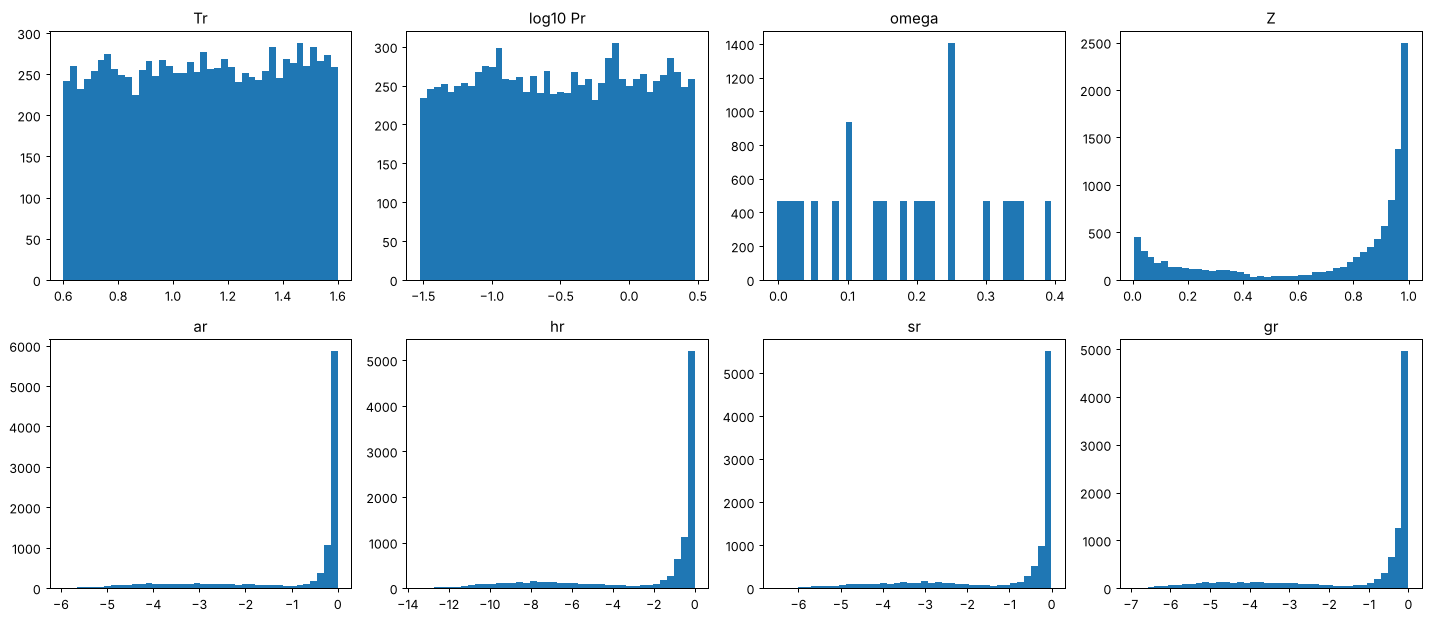

In [7]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, c in zip(ax.ravel(), ['Tr', 'Pr', 'omega', 'Z', 'ar', 'hr', 'sr', 'gr']):
    a.hist(np.log10(df[c]) if c == 'Pr' else df[c], bins=40); a.set_title('log10 Pr' if c == 'Pr' else c)
plt.tight_layout()

## Correlation matrix

,Tr,Pr,omega,Z,ar,hr,sr,gr,lnphi
Tr,1.00,0.00,-0.01,0.69,0.71,0.70,0.68,0.71,0.61
Pr,0.00,1.00,-0.00,-0.42,-0.27,-0.31,-0.32,-0.30,-0.43
omega,-0.01,-0.00,1.00,-0.02,-0.07,-0.11,-0.16,-0.06,-0.06
Z,0.69,-0.42,-0.02,1.00,0.92,0.94,0.93,0.95,0.74
ar,0.71,-0.27,-0.07,0.92,1.00,0.99,0.98,1.00,0.87
hr,0.70,-0.31,-0.11,0.94,0.99,1.00,0.99,1.00,0.87
sr,0.68,-0.32,-0.16,0.93,0.98,0.99,1.00,0.98,0.86
gr,0.71,-0.30,-0.06,0.95,1.00,1.00,0.98,1.00,0.86
lnphi,0.61,-0.43,-0.06,0.74,0.87,0.87,0.86,0.86,1.00


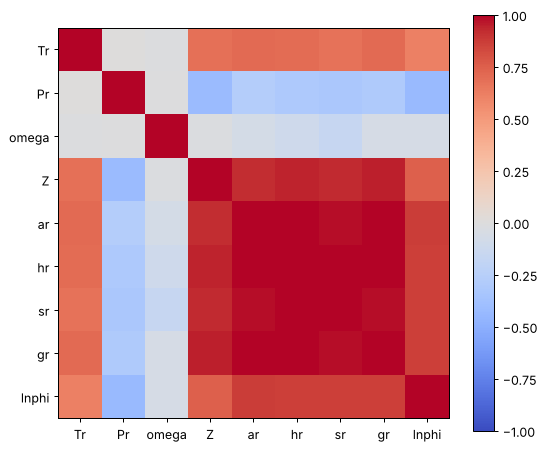

In [8]:
cols = ['Tr', 'Pr', 'omega', 'Z', 'ar', 'hr', 'sr', 'gr', 'lnphi']
C = df[cols].assign(Pr=np.log(df.Pr)).corr()
plt.figure(figsize=(7, 6)); plt.imshow(C, cmap='coolwarm', vmin=-1, vmax=1); plt.xticks(range(len(cols)), cols); plt.yticks(range(len(cols)), cols); plt.colorbar(); C.round(2)

## State space coloured by phase

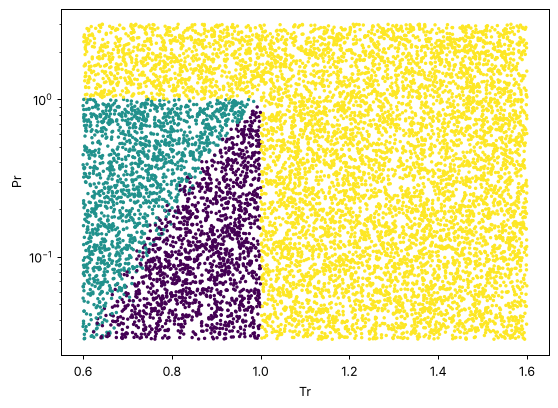

In [9]:
plt.figure(figsize=(7, 5)); plt.scatter(df.Tr, df.Pr, c=df.phase, s=3, cmap='viridis'); plt.yscale('log'); plt.xlabel('Tr'); plt.ylabel('Pr')